# Analysis 2: How long does a video stay on the trending list?

**Business question.** Once a video trends, how many days does it stay on the list, and does that differ by country and category? Longer time on the list means more days of free exposure.

**Method.** Survival analysis. The duration is the number of days a video appeared on a country's list. The event is leaving the list. Videos still on the list on 2024-04-15 have not left yet, so their duration is right-censored: we know they lasted at least that long. Kaplan-Meier curves use that partial information instead of dropping or miscounting those videos. Videos already trending on the first day of the data are left out because their earlier days are unknown.

Countries and categories are compared with log-rank tests, median survival, and restricted mean survival time (RMST): the average number of days on the list within the first 15 days.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import median_survival_times, restricted_mean_survival_time

from streampulse.analysis import load_trending_durations
from streampulse.charts import COUNTRIES, COUNTRY_COLORS, COUNTRY_NAMES, apply_chart_style
from streampulse.database import connect

RMST_HORIZON_DAYS = 15

apply_chart_style()
with connect() as connection:
    durations = load_trending_durations(connection)

durations.groupby("country").agg(
    videos=("video_id", "size"),
    left_list=("left_list", "sum"),
    still_trending_at_end=("left_list", lambda left: (left == 0).sum()),
).loc[COUNTRIES]

,videos,left_list,still_trending_at_end
country,,,
IN,78676,78487,189
US,46942,46742,200
GB,47407,47207,200


Only 589 videos (0.3%) are censored, so Kaplan-Meier will give almost the same medians as simply counting days. It is still the correct method, and it gives two things a plain average does not: a confidence interval for the median and the daily exit rate.

In [2]:
def fit_kaplan_meier(group_durations, label):
    return KaplanMeierFitter(label=label).fit(group_durations["days_trending"], group_durations["left_list"])


def survival_summary(fitter):
    median_ci = median_survival_times(fitter.confidence_interval_)
    return {
        "median_days": fitter.median_survival_time_,
        "median_ci_low": median_ci.iloc[0, 0],
        "median_ci_high": median_ci.iloc[0, 1],
        "rmst_15_days": restricted_mean_survival_time(fitter, t=RMST_HORIZON_DAYS),
    }

## 1. Survival curves by country

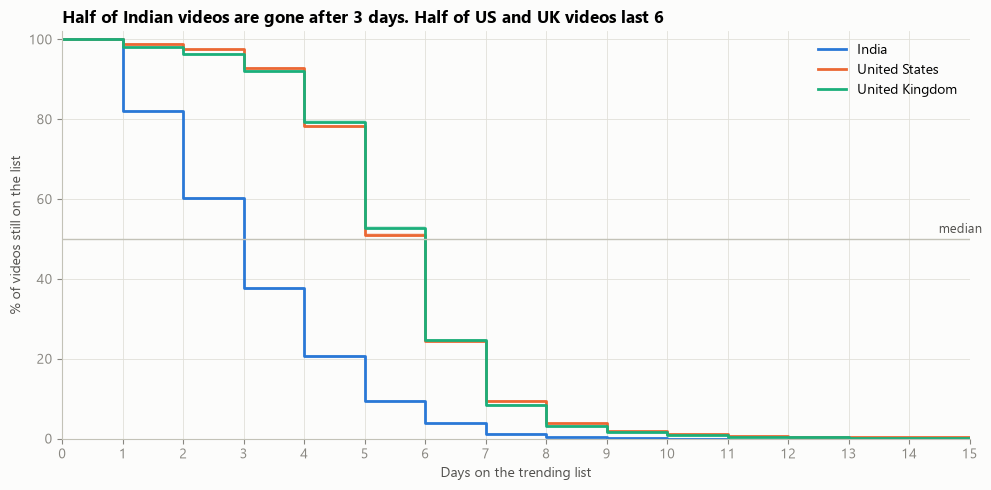

Log-rank test across countries: chi-squared = 64,832, p = 0


,median_days,median_ci_low,median_ci_high,rmst_15_days
IN,3.0,3.0,3.0,3.15
US,6.0,6.0,6.0,5.61
GB,6.0,6.0,6.0,5.58


In [3]:
country_fitters = {
    country: fit_kaplan_meier(durations[durations["country"] == country], COUNTRY_NAMES[country])
    for country in COUNTRIES
}

fig, ax = plt.subplots(figsize=(10, 5))
for country, fitter in country_fitters.items():
    survival = fitter.survival_function_.iloc[:, 0]
    ci = fitter.confidence_interval_
    ax.step(survival.index, 100 * survival, where="post", color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
    ax.fill_between(ci.index, 100 * ci.iloc[:, 0], 100 * ci.iloc[:, 1], step="post",
                    color=COUNTRY_COLORS[country], alpha=0.2, linewidth=0)
ax.axhline(50, color="#c3c2b7", linewidth=1)
ax.text(15.2, 51.5, "median", fontsize=9, color="#52514e", ha="right")
ax.set_xlim(0, 15)
ax.set_ylim(0, 102)
ax.set_xticks(range(0, 16))
ax.set_xlabel("Days on the trending list")
ax.set_ylabel("% of videos still on the list")
ax.set_title("Half of Indian videos are gone after 3 days. Half of US and UK videos last 6")
ax.legend()
plt.tight_layout()
plt.show()

country_logrank = multivariate_logrank_test(durations["days_trending"], durations["country"], durations["left_list"])
print(f"Log-rank test across countries: chi-squared = {country_logrank.test_statistic:,.0f}, "
      f"p = {country_logrank.p_value:.1g}")
pd.DataFrame({country: survival_summary(fitter) for country, fitter in country_fitters.items()}).T.round(2)

## 2. How videos leave the list

The daily exit rate is the share of videos still on the list at the start of a day that are gone the next day (the hazard). It shows the shape of a video's life on the list, which the median alone hides. Days with fewer than 100 videos still on the list are not shown, because the rate becomes noise.

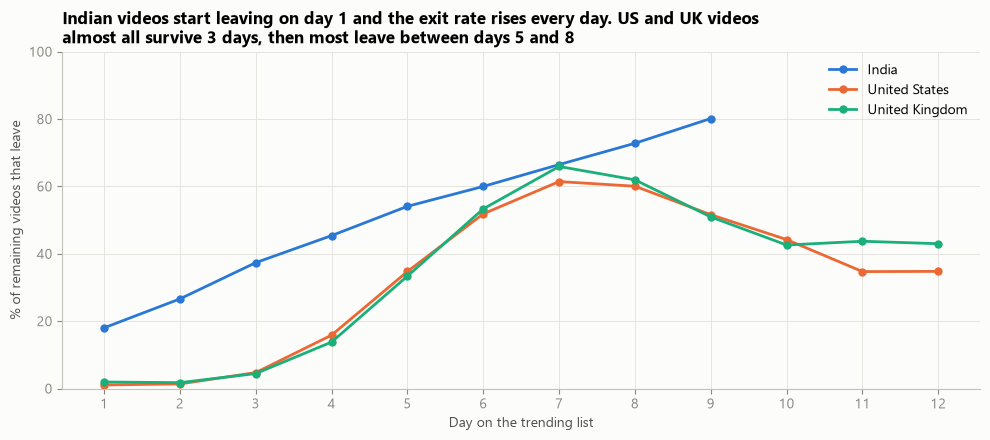

event_at,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0
IN,18.0,26.6,37.4,45.4,54.1,60.0,66.5,72.8,80.1,NaN,NaN,NaN
US,1.1,1.4,4.8,15.9,34.7,51.9,61.4,60.1,51.6,44.2,34.7,34.8
GB,2.0,1.8,4.5,13.8,33.4,53.3,65.9,61.9,50.9,42.6,43.7,43.0


In [4]:
exit_rates = pd.DataFrame({
    country: (fitter.event_table["observed"] / fitter.event_table["at_risk"])
             .where(fitter.event_table["at_risk"] >= 100)
    for country, fitter in country_fitters.items()
}).loc[1:12]

fig, ax = plt.subplots(figsize=(10, 4.5))
for country in COUNTRIES:
    ax.plot(exit_rates.index, 100 * exit_rates[country], marker="o", markersize=5,
            color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country])
ax.set_xticks(range(1, 13))
ax.set_ylim(0, 100)
ax.set_xlabel("Day on the trending list")
ax.set_ylabel("% of remaining videos that leave")
ax.set_title("Indian videos start leaving on day 1 and the exit rate rises every day. US and UK videos\n"
             "almost all survive 3 days, then most leave between days 5 and 8")
ax.legend()
plt.tight_layout()
plt.show()

(100 * exit_rates).round(1).T

## 3. Categories within each country

Log-rank tests across categories with at least 200 videos, run separately in each country. With tens of thousands of videos the tests will be significant, so the size of the differences is read from RMST.

In [5]:
category_rows = []
for (country, category), group in durations.groupby(["country", "category"]):
    if len(group) >= 200:
        category_rows.append({"country": country, "category": category, "videos": len(group),
                              **survival_summary(fit_kaplan_meier(group, category))})
category_survival = pd.DataFrame(category_rows)

for country in COUNTRIES:
    country_durations = durations[durations["country"] == country]
    large_categories = country_durations.groupby("category").filter(lambda rows: len(rows) >= 200)
    logrank = multivariate_logrank_test(large_categories["days_trending"], large_categories["category"],
                                        large_categories["left_list"])
    country_rmst = category_survival.loc[category_survival["country"] == country, "rmst_15_days"]
    print(f"{country}: {large_categories['category'].nunique()} categories, log-rank chi-squared = "
          f"{logrank.test_statistic:,.0f}, p = {logrank.p_value:.1g}, RMST ranges {country_rmst.min():.2f} to "
          f"{country_rmst.max():.2f} days")

IN: 13 categories, log-rank chi-squared = 3,778, p = 0, RMST ranges 2.72 to 4.02 days
US: 14 categories, log-rank chi-squared = 883, p = 2e-180, RMST ranges 5.06 to 5.92 days


GB: 13 categories, log-rank chi-squared = 869, p = 3e-178, RMST ranges 4.99 to 5.94 days


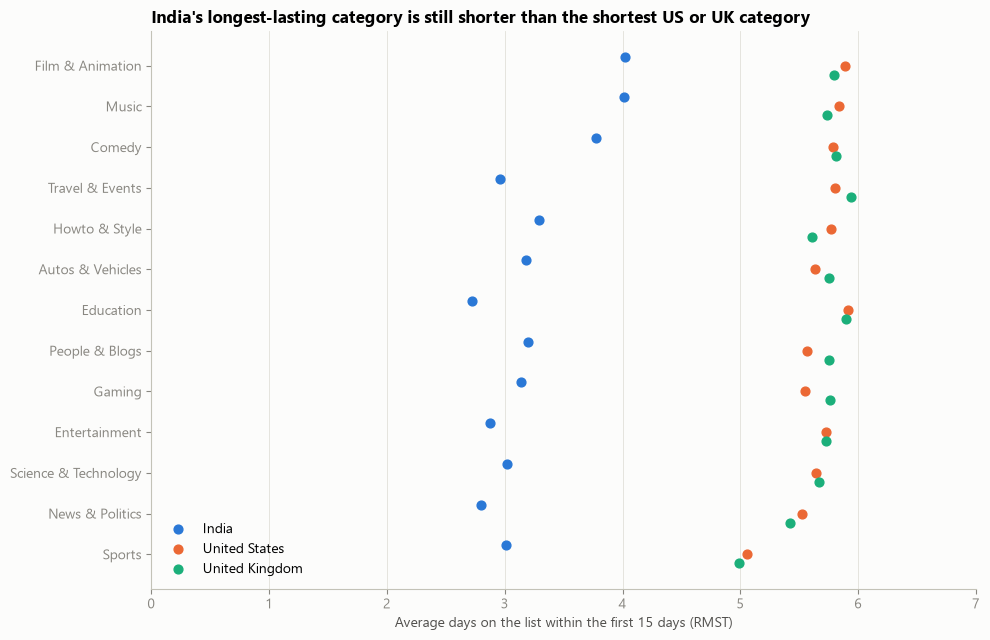

country,IN,US,GB
category,,,
Film & Animation,4.02,5.88,5.79
Music,4.01,5.83,5.74
Comedy,3.77,5.79,5.81
Travel & Events,2.96,5.81,5.94
Howto & Style,3.29,5.77,5.61
Autos & Vehicles,3.18,5.64,5.75
Education,2.72,5.92,5.90
People & Blogs,3.20,5.56,5.75
Gaming,3.14,5.54,5.76


In [6]:
shared_categories = (
    category_survival.groupby("category").filter(lambda rows: rows["country"].nunique() == 3)
)
category_order = shared_categories.groupby("category")["rmst_15_days"].mean().sort_values().index

fig, ax = plt.subplots(figsize=(10, 6.5))
for offset, country in zip([0.22, 0, -0.22], COUNTRIES):
    country_rows = shared_categories[shared_categories["country"] == country].set_index("category").reindex(category_order)
    ax.scatter(country_rows["rmst_15_days"], np.arange(len(category_order)) + offset, s=40,
               color=COUNTRY_COLORS[country], label=COUNTRY_NAMES[country], zorder=3)
ax.set_yticks(range(len(category_order)), category_order)
ax.set_xlim(0, 7)
ax.set_xlabel("Average days on the list within the first 15 days (RMST)")
ax.grid(axis="y", visible=False)
ax.set_title("India's longest-lasting category is still shorter than the shortest US or UK category")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

shared_categories.pivot(index="category", columns="country", values="rmst_15_days")[COUNTRIES].loc[category_order[::-1]].round(2)

## Finding

**Indian videos stay on the trending list about half as long as US and UK videos, in every category.**

- Median time on the list is 3 days in India and 6 days in the US and UK (log-rank chi-squared 64,832, p < 0.001). Within the first 15 days, the average is 3.15 days in India against 5.61 (US) and 5.58 (UK).
- The shape differs, not just the length. In India 18% of videos are gone after one day and the exit rate rises every day after. In the US and UK fewer than 5% leave on each of the first three days, then most leave between days 5 and 8 (52% to 53% of those remaining leave on day 6). That looks like a list that holds videos for about a week by design, against one that rotates continuously.
- The gap holds within every category present in all three countries. India's longest-lasting category (Film & Animation, 4.02 days) is shorter than the shortest US or UK category (UK Sports, 4.99 days). India's short life on the list is not explained by its category mix.
- Categories differ less within a country: RMST ranges 2.72 to 4.02 days in India, 5.06 to 5.92 in the US and 4.99 to 5.94 in the UK. Sports is the shortest-lived category in the US and UK; Film & Animation and Music last longest in India.
- Only 0.3% of videos were censored, so the Kaplan-Meier medians match the simple medians from the SQL queries. Survival analysis confirmed those numbers rather than changing them.

**Limitations**

- Days on the list counts list appearances. 7.6% of videos have a gap in their run, from dropping off and coming back or from one of the 20 days with no list, so a few runs are undercounted by a day.
- The list shows at most 200 videos a day. Duration depends on what else is trending, not only on the video itself.
- This is descriptive. It shows where and in which categories videos last longer, not why.